# Разбор профильной математики: 19 задач × 3 повтора

Ноутбук — точка входа для человека со стороны. Он читает сохранённые условия и ответы агентов, заново строит таблицы и графики; **не вызывает модель и не выполняет сетевых запросов**.

План: `docs/eda/04-annotation/04-agent-run-plan.md`. Входы: один вариант «Решу ЕГЭ», промпт A после исследования 02.1. Это development-набор, а не репрезентативная выборка ЕГЭ. Результаты модели — кандидаты, а не эталоны.

Выполнить ячейки сверху вниз. В ячейке ниже можно заменить RUN и TASK_POSITION. Для просмотра иных условий меняется только TASK_POSITION.

In [1]:
from pathlib import Path
import sys, os
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'scripts/annotation_pipeline.py').exists())
sys.path.insert(0, str(ROOT / 'scripts'))
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.venv/matplotlib'))
from annotation_pipeline import build, read, merge_catalog
from annotation_report import rows, html_table, compare_html, plots, report
from IPython.display import display, HTML, Image, SVG, Markdown
RUN = ROOT / 'data/annotation/runs/2026-10-25-A-19x3'
TASK_POSITION = 1
manifest = read(RUN / 'manifest.json')
display(Markdown(f"**Запуск:** `{manifest['run_id']}`; **ожидается:** {len(manifest['jobs'])} ответов.\n\n**Исходный commit:** `{manifest['git_commit']}`. Параметры модели: {manifest['model_parameters']}."))

**Запуск:** `2026-10-25-A-19x3`; **ожидается:** 57 ответов.

**Исходный commit:** `d3cb96f21c758fa8072a2362e069a316c2462e23`. Параметры модели: None.

## 1. Проверка сохранности и перестроение таблиц

Входы: manifest, запросы, изображения, raw, сохранённые reviews и соответствия KC (если имеются). Выходы: `derived/*.csv`, summary и provenance. Исходные ответы не меняются. Недостающие ответы остаются в знаменателе.

In [2]:
merge_catalog(RUN)
summary = build(RUN)
display(HTML(html_table([summary])))
display(HTML(html_table(rows(RUN, 'status'))))

expected,present,json_valid,structure_valid,math_reviewed,fully_mapped_responses,available_jaccard_pairs,eligible_corpus_responses,eligible_distinct_tasks,canonical_kcs_in_eligible_tasks,singleton_fraction,corpus_policy,prerequisite_inference,official_fipi_coverage,math_status_counts,annotation_status_counts,review_scope,mapping_scope,mean_jaccard_over_available_tasks,tasks_with_jaccard
57,57,57,57,57,57,57,57,19,155,0.9870967741935484,"union across mathematically passed, annotation accepted, fully mapped repeats; task counted once",False,not_computed_no_mapping,{'passed': 57},{'accepted': 57},"Preliminary LLM review, not independent expert validation",Conservative draft matching of KC definitions; composite and differently scoped definitions kept separate; not an approved skill catalog,0.4966304650515177,19


job_id,task_id,repeat,raw_path,raw_sha256,json_valid,structure_valid,errors,steps,kcs,methods,math_status,annotation_status
699085_r1,699085,1,raw/699085_r1.txt,e498fd8ad483927052331739d75d9cae84d879a2b65b48e5259b68ea789dcf0d,True,True,,2,2,1,passed,accepted
699085_r2,699085,2,raw/699085_r2.txt,4f2fd64a651272bb0185987047d8629b8f9b787f1f64de9784abdc564b486781,True,True,,2,2,1,passed,accepted
699085_r3,699085,3,raw/699085_r3.txt,bb40c59aab706511b4f92bc1ba477ea45df33e0c05e903c520ca7edf094bd829,True,True,,2,2,1,passed,accepted
699086_r1,699086,1,raw/699086_r1.txt,e97b19895d70a8ceeba20cbaf8d3cc2e1207f1db539be8a901107108765c47a7,True,True,,3,4,1,passed,accepted
699086_r2,699086,2,raw/699086_r2.txt,dd88ffae0d144cb1ec5426e042de3859f1cf535b33ab53126230fb59a5fe93d4,True,True,,3,3,1,passed,accepted
699086_r3,699086,3,raw/699086_r3.txt,fc1cfbd2acb8a919af8fbd78b212d19be01edc91fc3d2eb873806e4669144fff,True,True,,3,4,1,passed,accepted
699087_r1,699087,1,raw/699087_r1.txt,bd711f8227058e2f023eb2c0c41f5880ed11ad1b5cc8098886647a416b144a98,True,True,,2,4,1,passed,accepted
699087_r2,699087,2,raw/699087_r2.txt,f8e57a2cf2fe2f86e6f55f69128ebc861383ad42729f1b1a32dcd9d454456431,True,True,,3,4,1,passed,accepted
699087_r3,699087,3,raw/699087_r3.txt,46529c308dbc1dce935bf0116436ab52c8da1ad585b786d7d9be7f083aecfcd2,True,True,,2,3,1,passed,accepted
699088_r1,699088,1,raw/699088_r1.txt,59d118ac060c11a401c837c2ac5af8ead091af3411e28c388cae4453d569d676,True,True,,2,2,1,passed,accepted


## 2. Условие и три независимых разбора рядом

Здесь только сохранённое условие и его изображения. Ниже — исходные ответы, без молчаливого исправления. Статус `solved` — самооценка решавшей модели, не заключение проверяющего.

**Позиция 1, ID 699085**

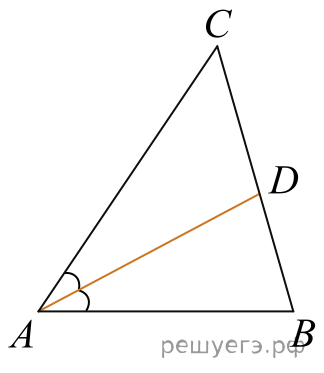

In [3]:
task = next(t for t in manifest['tasks'] if t['position'] == TASK_POSITION)
payload = read(RUN / 'inputs' / f"{task['task_id']}.json")
display(Markdown(f"**Позиция {TASK_POSITION}, ID {task['task_id']}**"))
display(HTML('<p>' + __import__('html').escape(payload['statement']) + '</p>'))
for image in task['images']:
    display(Image(filename=str(RUN / image['path'])))
display(HTML(compare_html(RUN, TASK_POSITION)))

## 3. Математическая проверка и качество разметки

Рецензия хранится отдельно от raw, с хешем проверенного ответа и основаниями оценки. Отсутствие рецензии означает «не проверено». Согласие трёх агентов не является доказательством правильности.

In [4]:
review_path = RUN / 'reviews' / f"{task['task_id']}.json"
if review_path.exists():
    review = read(review_path)
    display(HTML('<pre>' + __import__('html').escape(__import__('json').dumps(review, ensure_ascii=False, indent=2)) + '</pre>'))
else:
    display(Markdown('Для этой задачи содержательная рецензия ещё не сохранена.'))

## 4. Происхождение таблиц и структура ответов

`steps` и `kcs` содержат исходные формулировки с job_id, task_id, повтором и raw_path. `step_kc` и `method_steps` сохраняют связи и порядок. Графики структуры используют все структурно корректные ответы; это **не** частоты проверенных умений.

**steps.csv:** 232 строк; первые 8:

job_id,task_id,repeat,raw_path,step_id,order,action,result
699085_r1,699085,1,raw/699085_r1.txt,s1,1,Применить определение биссектрисы AD к углу BAC.,"Углы BAD и CAD равны, поэтому угол BAC = 2·30° = 60°."
699085_r1,699085,1,raw/699085_r1.txt,s2,2,"Выразить угол B через два известных угла треугольника ABC, используя сумму углов треугольника.",Угол B = 180° − 60° − 54° = 66°. Ответ: 66.
699085_r2,699085,2,raw/699085_r2.txt,s1,1,"Использовать свойство биссектрисы AD, чтобы найти полный угол A треугольника ABC.","Углы BAD и CAD равны, поэтому угол A = 2 · 30° = 60°."
699085_r2,699085,2,raw/699085_r2.txt,s2,2,Применить сумму углов треугольника ABC для нахождения угла B.,Угол B = 180° − 60° − 54° = 66°. Ответ: 66.
699085_r3,699085,3,raw/699085_r3.txt,s1,1,Применить свойство биссектрисы AD к углу A и найти полный угол треугольника при вершине A.,"Углы CAD и DAB равны, поэтому угол A = 2 · 30° = 60°."
699085_r3,699085,3,raw/699085_r3.txt,s2,2,Применить сумму внутренних углов треугольника ABC и найти угол B.,Угол B = 180° − 60° − 54° = 66°. Ответ: 66.
699086_r1,699086,1,raw/699086_r1.txt,s1,1,Считать с рисунка координаты начал и концов векторов и вычесть координаты начала из координат конца.,"Вектор a направлен от (1; 1) к (3; 5), поэтому a = (3 − 1; 5 − 1) = (2; 4). Вектор b направлен от (2; 1) к (6; 5), поэтому b = (6 − 2; 5 − 1) = (4; 4)."
699086_r1,699086,1,raw/699086_r1.txt,s2,2,Сложить соответствующие координаты векторов a и b.,a + b = (2 + 4; 4 + 4) = (6; 8).


**kcs.csv:** 276 строк; первые 8:

job_id,task_id,repeat,raw_path,kc_id,name,description
699085_r1,699085,1,raw/699085_r1.txt,k1,"Вычислять угол по его половине, заданной биссектрисой","Использовать равенство углов, на которые биссектриса делит угол, и находить весь угол удвоением одной из его половин."
699085_r1,699085,1,raw/699085_r1.txt,k2,Находить третий угол треугольника по двум известным,Вычитать сумму двух известных внутренних углов треугольника из 180 градусов.
699085_r2,699085,2,raw/699085_r2.txt,k1,"Находить полный угол по половине, образованной биссектрисой","Использовать равенство двух углов, на которые биссектриса делит исходный угол, и удваивать известную половину."
699085_r2,699085,2,raw/699085_r2.txt,k2,Находить угол треугольника по двум другим углам,Вычитать сумму двух известных внутренних углов из 180° для определения третьего угла треугольника.
699085_r3,699085,3,raw/699085_r3.txt,k1,"Находить полный угол по его половине, заданной биссектрисой","Использовать равенство двух углов, на которые биссектриса делит угол, и удваивать известную половину для получения полного угла."
699085_r3,699085,3,raw/699085_r3.txt,k2,Находить неизвестный угол треугольника по двум известным,Вычитать сумму двух известных внутренних углов треугольника из 180° для вычисления третьего угла.
699086_r1,699086,1,raw/699086_r1.txt,k1,Считывать координаты точек по координатной сетке,Определять абсциссу и ординату отмеченной точки с учётом направлений осей и масштаба координатной сетки.
699086_r1,699086,1,raw/699086_r1.txt,k2,Вычислять координаты направленного вектора по его концам,Вычитать координаты начала вектора из соответствующих координат его конца.


**methods.csv:** 72 строк; первые 8:

...

**step_kc.csv:** 330 строк; первые 8:

job_id,task_id,repeat,raw_path,step_id,kc_id
699085_r1,699085,1,raw/699085_r1.txt,s1,k1
699085_r1,699085,1,raw/699085_r1.txt,s2,k2
699085_r2,699085,2,raw/699085_r2.txt,s1,k1
699085_r2,699085,2,raw/699085_r2.txt,s2,k2
699085_r3,699085,3,raw/699085_r3.txt,s1,k1
699085_r3,699085,3,raw/699085_r3.txt,s2,k2
699086_r1,699086,1,raw/699086_r1.txt,s1,k1
699086_r1,699086,1,raw/699086_r1.txt,s1,k2


**method_steps.csv:** 232 строк; первые 8:

job_id,task_id,repeat,raw_path,method_id,step_id,order
699085_r1,699085,1,raw/699085_r1.txt,m1,s1,1
699085_r1,699085,1,raw/699085_r1.txt,m1,s2,2
699085_r2,699085,2,raw/699085_r2.txt,m1,s1,1
699085_r2,699085,2,raw/699085_r2.txt,m1,s2,2
699085_r3,699085,3,raw/699085_r3.txt,m1,s1,1
699085_r3,699085,3,raw/699085_r3.txt,m1,s2,2
699086_r1,699086,1,raw/699086_r1.txt,m1,s1,1
699086_r1,699086,1,raw/699086_r1.txt,m1,s2,2


**run-status.svg** ← `derived/summary.json`

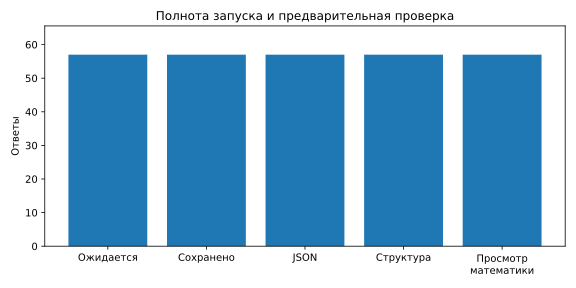

**response-structure.svg** ← `derived/status.csv`

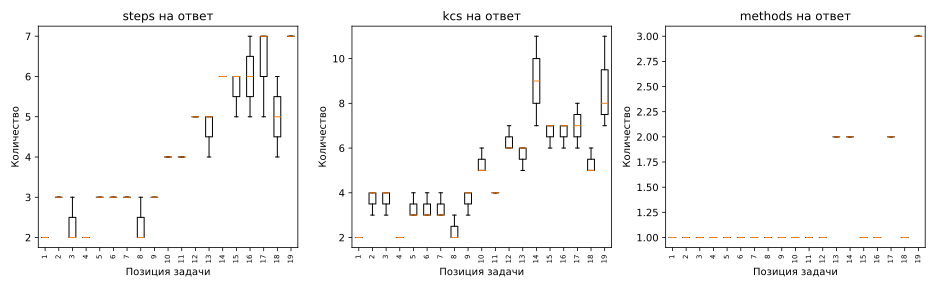

**kc-stability.svg** ← `derived/stability_summary.csv`

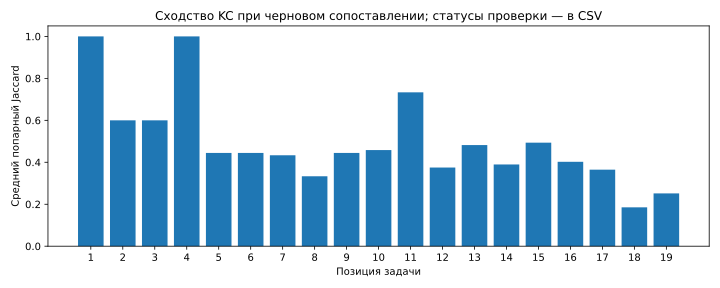

**kc-frequency.svg** ← `derived/kc_frequency.csv`

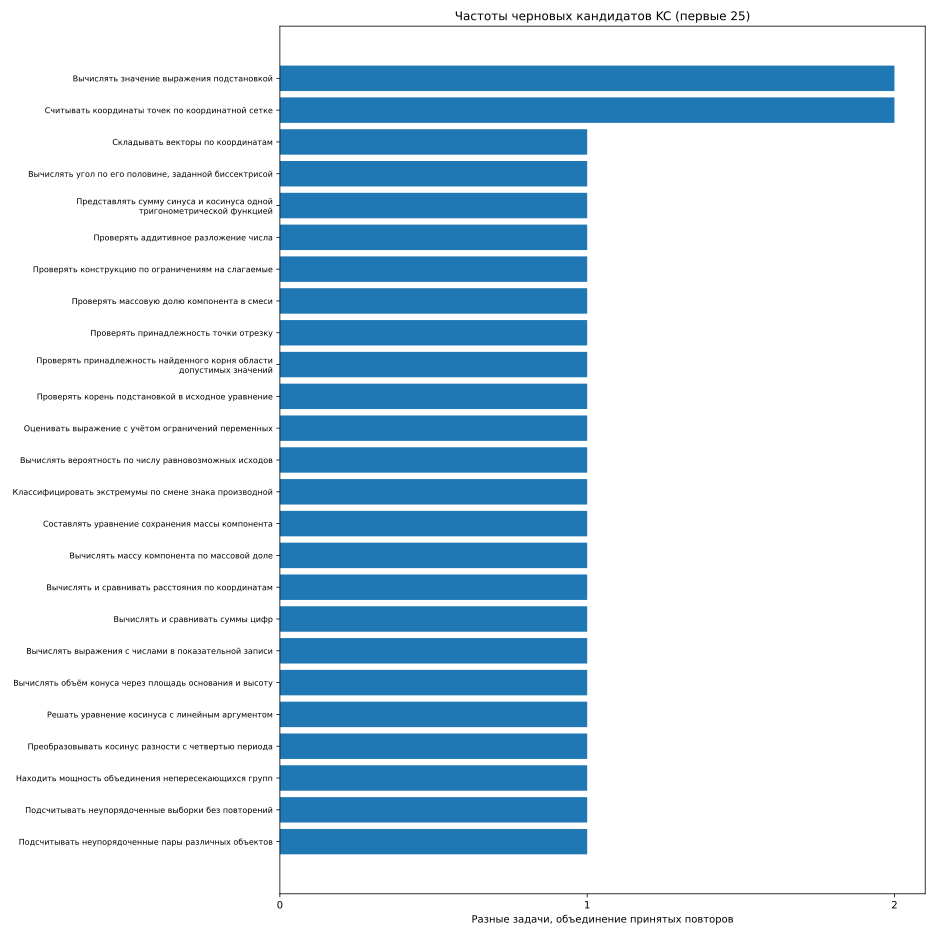

Полный автономный просмотр всех задач: C:\Users\U_M35CB\Documents\ВШЭ\proactive-ai-tutor-65\data\annotation\runs\2026-10-25-A-19x3\derived\review.html


In [5]:
for name in ['steps', 'kcs', 'methods', 'step_kc', 'method_steps']:
    data = rows(RUN, name)
    display(Markdown(f"**{name}.csv:** {len(data)} строк; первые 8:"))
    display(HTML(html_table(data[:8])))
figures = plots(RUN)
for figure in figures:
    display(Markdown(f"**{figure['file']}** ← `derived/{figure['source']}`"))
    display(SVG(filename=str(RUN / 'derived' / figure['file'])))
report_path = report(RUN)
print("Полный автономный просмотр всех задач:", report_path)

## 5. Общий каталог и стабильность

Общий KC определяется по действию, объектам и условиям применения; равенства имён недостаточно. `catalog.json` содержит определения, `kc_mapping.json` — исходный KC → общий KC, основание и хеш ответа. Это сохраняемые смысловые решения, а не автоматический результат парсинга.

Jaccard рассчитывается по трём парам повторов задачи только при полном сопоставлении KC. Показывается доступность пар и математический статус. Высокое сходство не гарантирует правильность.

In [6]:
for filename in ['catalog.json', 'kc_mapping.json']:
    path = RUN / filename
    if path.exists():
        values = read(path)
        display(Markdown(f"**{filename}:** {len(values)} записей"))
        display(HTML(html_table(values[:10])))
    else:
        display(Markdown(f"**{filename}:** ещё не подготовлен; смысловое сопоставление не подменяется совпадением названий."))
display(HTML(html_table(rows(RUN, 'stability'))))
display(HTML(html_table(rows(RUN, "stability_summary"))))

**catalog.json:** 155 записей

id,name,description,status,rationale
kc_add_vector_coordinates,Складывать векторы по координатам,Получать координаты суммы векторов сложением их соответствующих координат.,candidate,Объединены формулировки одной операции с одинаковыми объектами и условиями; исходная составность сохранена.
kc_angle_from_bisector_half,"Вычислять угол по его половине, заданной биссектрисой","Использовать равенство углов, на которые биссектриса делит угол, и находить весь угол удвоением одной из его половин.",candidate,Объединены формулировки одной операции с одинаковыми объектами и условиями; исходная составность сохранена.
kc_auxiliary_angle_linear_sine_cosine,Представлять сумму синуса и косинуса одной тригонометрической функцией,Подбирать множитель и сдвиг аргумента по формуле сложения для линейной комбинации синуса и косинуса одного аргумента.,candidate,"Смысловые синонимы: совпадают действие, математические объекты и условия применения. Составные действия не разложены."
kc_check_distinct_additive_decomposition,Проверять аддитивное разложение числа,"Проверять, что выбранные натуральные слагаемые различны и их сумма равна заданному числу.",candidate,"Отдельный кандидат: объём операции сохранён по исходному определению, без разбиения или приравнивания более простому навыку."
kc_check_distinct_sum_and_digit_sum_example,Проверять конструкцию по ограничениям на слагаемые,"Вычислять сумму предложенных натуральных слагаемых и суммы их цифр, проверять различность и выполнение заданных ограничений.",candidate,Объединены формулировки одной операции с одинаковыми объектами и условиями; исходная составность сохранена.
kc_check_mixture_component_fraction,Проверять массовую долю компонента в смеси,Делить суммарную массу компонента на массу смеси и сопоставлять полученную долю с заданной.,candidate,"Отдельный кандидат: сохраняется исходный объём операции, включая ограничения или составные действия; равенство с более простым определением не предполагается."
kc_check_point_on_segment,Проверять принадлежность точки отрезку,"Устанавливать, что точка прямой лежит между концами отрезка, используя диапазон координаты или параметр внутреннего деления.",candidate,"Отдельный кандидат: объём операции сохранён по исходному определению, без разбиения или приравнивания более простому навыку."
kc_check_root_domain,Проверять принадлежность найденного корня области допустимых значений,Сопоставлять полученное значение неизвестной с ограничениями исходного уравнения и сохранять только допустимые значения.,candidate,"Отдельный кандидат: объём операции сохранён по исходному определению, без разбиения или приравнивания более простому навыку."
kc_check_root_substitution_defined_equation,Проверять корень подстановкой в исходное уравнение,"Подставлять найденное значение переменной, проверять определённость выражений и равенство обеих частей исходного уравнения.",candidate,Объединены формулировки одной операции с одинаковыми объектами и условиями; исходная составность сохранена.
kc_circle_bounds_transform_exponential_estimate,Оценивать выражение с учётом ограничений переменных,"Выводить границы переменных из уравнения окружности, преобразовывать выражение в сумму и применять оценки показательной функции и неотрицательных произведений.",candidate,"Отдельный кандидат: объём операции сохранён по исходному определению, без разбиения или приравнивания более простому навыку."


**kc_mapping.json:** 276 записей

job_id,kc_id,canonical_id,raw_sha256,reason
699085_r1,k1,kc_angle_from_bisector_half,e498fd8ad483927052331739d75d9cae84d879a2b65b48e5259b68ea789dcf0d,"Объединены формулировки одной операции с одинаковыми объектами и условиями; исходная составность сохранена. Область кандидата: Использовать равенство углов, на которые биссектриса делит угол, и находить весь угол удвоением одной из его половин."
699085_r1,k2,kc_triangle_third_angle,e498fd8ad483927052331739d75d9cae84d879a2b65b48e5259b68ea789dcf0d,Объединены формулировки одной операции с одинаковыми объектами и условиями; исходная составность сохранена. Область кандидата: Вычитать сумму двух известных внутренних углов треугольника из 180 градусов.
699085_r2,k1,kc_angle_from_bisector_half,4f2fd64a651272bb0185987047d8629b8f9b787f1f64de9784abdc564b486781,"Объединены формулировки одной операции с одинаковыми объектами и условиями; исходная составность сохранена. Область кандидата: Использовать равенство углов, на которые биссектриса делит угол, и находить весь угол удвоением одной из его половин."
699085_r2,k2,kc_triangle_third_angle,4f2fd64a651272bb0185987047d8629b8f9b787f1f64de9784abdc564b486781,Объединены формулировки одной операции с одинаковыми объектами и условиями; исходная составность сохранена. Область кандидата: Вычитать сумму двух известных внутренних углов треугольника из 180 градусов.
699085_r3,k1,kc_angle_from_bisector_half,bb40c59aab706511b4f92bc1ba477ea45df33e0c05e903c520ca7edf094bd829,"Объединены формулировки одной операции с одинаковыми объектами и условиями; исходная составность сохранена. Область кандидата: Использовать равенство углов, на которые биссектриса делит угол, и находить весь угол удвоением одной из его половин."
699085_r3,k2,kc_triangle_third_angle,bb40c59aab706511b4f92bc1ba477ea45df33e0c05e903c520ca7edf094bd829,Объединены формулировки одной операции с одинаковыми объектами и условиями; исходная составность сохранена. Область кандидата: Вычитать сумму двух известных внутренних углов треугольника из 180 градусов.
699086_r1,k1,kc_read_point_coordinates_grid,e97b19895d70a8ceeba20cbaf8d3cc2e1207f1db539be8a901107108765c47a7,Объединены формулировки одной операции с одинаковыми объектами и условиями; исходная составность сохранена. Область кандидата: Определять абсциссу и ординату отмеченной точки с учётом направлений осей и масштаба координатной сетки.
699086_r1,k2,kc_vector_coordinates_endpoints,e97b19895d70a8ceeba20cbaf8d3cc2e1207f1db539be8a901107108765c47a7,Объединены формулировки одной операции с одинаковыми объектами и условиями; исходная составность сохранена. Область кандидата: Вычитать координаты начала вектора из соответствующих координат его конца.
699086_r1,k3,kc_add_vector_coordinates,e97b19895d70a8ceeba20cbaf8d3cc2e1207f1db539be8a901107108765c47a7,Объединены формулировки одной операции с одинаковыми объектами и условиями; исходная составность сохранена. Область кандидата: Получать координаты суммы векторов сложением их соответствующих координат.
699086_r1,k4,kc_vector_length_coordinates,e97b19895d70a8ceeba20cbaf8d3cc2e1207f1db539be8a901107108765c47a7,Объединены формулировки одной операции с одинаковыми объектами и условиями; исходная составность сохранена. Область кандидата: Находить длину вектора в прямоугольной системе координат как квадратный корень из суммы квадратов его координат.


task_id,a,b,available,jaccard,both_math_passed
699085,699085_r1,699085_r2,True,1.0,True
699085,699085_r1,699085_r3,True,1.0,True
699085,699085_r2,699085_r3,True,1.0,True
699086,699086_r1,699086_r2,True,0.4,True
699086,699086_r1,699086_r3,True,1.0,True
699086,699086_r2,699086_r3,True,0.4,True
699087,699087_r1,699087_r2,True,1.0,True
699087,699087_r1,699087_r3,True,0.4,True
699087,699087_r2,699087_r3,True,0.4,True
699088,699088_r1,699088_r2,True,1.0,True


task_id,position,available_pairs,mean_jaccard,math_passed_pairs,mean_jaccard_math_passed
699085,1,3,1.0,3,1.0
699086,2,3,0.6,3,0.6
699087,3,3,0.6,3,0.6
699088,4,3,1.0,3,1.0
699089,5,3,0.4444444444444444,3,0.4444444444444444
699090,6,3,0.4444444444444444,3,0.4444444444444444
699091,7,3,0.43333333333333335,3,0.43333333333333335
699092,8,3,0.3333333333333333,3,0.3333333333333333
699093,9,3,0.4444444444444444,3,0.4444444444444444
699094,10,3,0.4583333333333333,3,0.4583333333333333


## 6. Повторяемость и сочетания KC между задачами

Отбор: математическая проверка `passed`, разметка `accepted`, полное сопоставление KC. Частоты считают разные задачи; три повтора не утраивают корпус. Политика объединения — KC встречался хотя бы в одном принятом повторе. Таблица `task_kc.csv` сохраняет присутствие отдельно по повторам; co-occurrence учитывает пару только если оба KC встретились вместе хотя бы в одном принятом повторе задачи. Разные альтернативные решения не создают искусственных пар.

Если отбор пока пуст, предметных частот нет. Официальное покрытие ФИПИ не рассчитывается без явного соответствия кодам.

In [7]:
for name in ['kc_frequency', 'task_kc', 'cooccurrence']:
    display(Markdown(f"**{name}.csv**"))
    display(HTML(html_table(rows(RUN, name))))
display(Markdown(f"**Доля единичных KC:** {summary['singleton_fraction']} (None = данных недостаточно)."))

**kc_frequency.csv**

canonical_id,name,distinct_tasks_any_accepted_repeat
kc_add_vector_coordinates,Складывать векторы по координатам,1
kc_angle_from_bisector_half,"Вычислять угол по его половине, заданной биссектрисой",1
kc_auxiliary_angle_linear_sine_cosine,Представлять сумму синуса и косинуса одной тригонометрической функцией,1
kc_check_distinct_additive_decomposition,Проверять аддитивное разложение числа,1
kc_check_distinct_sum_and_digit_sum_example,Проверять конструкцию по ограничениям на слагаемые,1
kc_check_mixture_component_fraction,Проверять массовую долю компонента в смеси,1
kc_check_point_on_segment,Проверять принадлежность точки отрезку,1
kc_check_root_domain,Проверять принадлежность найденного корня области допустимых значений,1
kc_check_root_substitution_defined_equation,Проверять корень подстановкой в исходное уравнение,1
kc_circle_bounds_transform_exponential_estimate,Оценивать выражение с учётом ограничений переменных,1


**task_kc.csv**

task_id,repeat,job_id,canonical_id
699085,1,699085_r1,kc_angle_from_bisector_half
699085,1,699085_r1,kc_triangle_third_angle
699085,2,699085_r2,kc_angle_from_bisector_half
699085,2,699085_r2,kc_triangle_third_angle
699085,3,699085_r3,kc_angle_from_bisector_half
699085,3,699085_r3,kc_triangle_third_angle
699086,1,699086_r1,kc_add_vector_coordinates
699086,1,699086_r1,kc_read_point_coordinates_grid
699086,1,699086_r1,kc_vector_coordinates_endpoints
699086,1,699086_r1,kc_vector_length_coordinates


**cooccurrence.csv**

kc_a,kc_b,distinct_tasks_same_accepted_repeat
kc_add_vector_coordinates,kc_read_and_compute_vector_coordinates,1
kc_add_vector_coordinates,kc_read_point_coordinates_grid,1
kc_add_vector_coordinates,kc_vector_coordinates_endpoints,1
kc_add_vector_coordinates,kc_vector_length_coordinates,1
kc_angle_from_bisector_half,kc_triangle_third_angle,1
kc_auxiliary_angle_linear_sine_cosine,kc_cosine_linear_argument_general_solution,1
kc_auxiliary_angle_linear_sine_cosine,kc_cosine_minus_quarter_turn_to_sine,1
kc_auxiliary_angle_linear_sine_cosine,kc_equivalent_equation_algebraic_transform,1
kc_auxiliary_angle_linear_sine_cosine,kc_general_cosine_argument_solutions,1
kc_auxiliary_angle_linear_sine_cosine,kc_linear_argument_periodic_series,1


**Доля единичных KC:** 0.9870967741935484 (None = данных недостаточно).

## 7. Выводы и ограничения

Этот ноутбук не превращает LLM-разбор в экспертный эталон. Содержательные выводы фиксируются в README запуска после рецензирования. Различаем техническую валидность, математическую правильность, качество детализации и стабильность. Статистика касается одного варианта; данных об освоении учениками нет.

`derived/provenance.json` связывает код, входы и таблицы хешами. `derived/figures.json` связывает каждый график с его таблицей. Повторное Run All восстанавливает анализ сохранённых ответов; генерация новых ответов — отдельная агентная процедура.